# 05 · Imitation: expert demonstrations → behaviour cloning → DAgger (MLP and GRU policies)

`results/FINAL_SPEC.md` §5, steps 1–3:
1. **Expert demonstrations** on all 980 training windows (perfect-foresight MILP re-planned every 4 h from the state reached).
2. **Behaviour cloning** (π₀): the policy network learns to copy the expert (cross-entropy; GPU).
3. **DAgger, 2 rounds:** the cloned policy drives on 300 random training windows; the expert labels every 8th state the policy
   actually reached; the policy is re-cloned on all labels. The round with the best validation reward is kept for PPO (notebook 06).
Two networks, 5 seeds each: **MLP** (current state) and **GRU** (deep sequence model over the last 2 hours of states).

In [1]:
%%writefile ../src/learn.py
"""Learned controller: behaviour cloning -> DAgger -> PPO, with an MLP or a GRU (deep sequence) policy network.
Written from notebooks/05_imitation.ipynb. Settings fixed in results/FINAL_SPEC.md section 5.

Data layout for cloning: F = states [N, 23]; IDX = [N, 8] row numbers in F of the last 8 states (oldest first, the first state
repeated at the start of an episode, exactly as the simulator stacks them); y = expert action; hold = cloning hold-out flag.
MLP input = F[IDX[:, -1]] (current state); GRU input = F[IDX] (last 2 hours)."""
import copy, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.torch_layers import BaseFeaturesExtractor
from sim import StreetEnv, N_OBS, load_bank, load_cfg, evaluate
from controllers import expert_label

K_HIST = 8                          # GRU: last 8 states = 2 hours
NETS = {"MLP": 1, "GRU": K_HIST}    # network -> states stacked in the observation
STEPS, EVAL_EVERY, PPO_LR = 1_000_000, 100_000, 1e-4
N_ROUNDS, ROLL_WINDOWS, LABEL_STRIDE = 2, 300, 8


class GRUExtractor(BaseFeaturesExtractor):
    """Last K states [K x 23] -> GRU (64 hidden) -> last hidden state, concatenated with the current state (64 + 23 = 87)."""
    def __init__(self, observation_space: spaces.Box, k=K_HIST, n_in=N_OBS, hidden=64):
        super().__init__(observation_space, features_dim=hidden + n_in)
        self.k, self.n_in = k, n_in
        self.gru = nn.GRU(n_in, hidden, batch_first=True)

    def forward(self, obs):
        x = obs.view(-1, self.k, self.n_in)
        _, h = self.gru(x)
        return torch.cat([h[-1], x[:, -1]], dim=1)


def make_ppo(env, seed, net, lr=PPO_LR):
    kw = dict(net_arch=[128, 128])
    if net == "GRU":
        kw.update(features_extractor_class=GRUExtractor, features_extractor_kwargs=dict(k=K_HIST, n_in=N_OBS, hidden=64))
    return PPO("MlpPolicy", env, learning_rate=lr, n_steps=2048, batch_size=256, n_epochs=10, gae_lambda=0.95, clip_range=0.2,
               ent_coef=0.01, gamma=0.995, policy_kwargs=kw, seed=seed, device="cpu", verbose=0)


def env_kw(net):
    return dict(shield=True, stack=NETS[net])


# ---------- behaviour cloning ----------
def stack_index(n_steps, offset, k=K_HIST):
    t = np.arange(n_steps)
    return (offset + np.maximum(t[:, None] - (k - 1) + np.arange(k)[None, :], 0)).astype(np.int64)


def clone(bank, train_eps, cfg, net, seed, F, IDX, y, hold, max_epochs=30, batch=1024):
    """Cross-entropy cloning into a fresh PPO policy (seed `seed`, the same initialisation PPO starts from); Adam 1e-3, batch 1024,
    epoch with the lowest hold-out cross-entropy kept. Runs on the GPU when available."""
    torch.manual_seed(seed); torch.backends.cudnn.deterministic = True
    model = make_ppo(StreetEnv(bank, train_eps, cfg, train=True, seed=seed, **env_kw(net)), seed, net)
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    pol = model.policy.to(dev); pol.set_training_mode(True)
    Ft, It, yt = torch.tensor(F, device=dev), torch.tensor(IDX if net == "GRU" else IDX[:, -1:], device=dev), torch.tensor(y, device=dev)
    X = lambda j: Ft[It[j]].reshape(len(j), -1)
    opt = torch.optim.Adam(pol.parameters(), lr=1e-3); rng = np.random.default_rng(seed)
    tr, ho = np.where(~hold)[0], torch.tensor(np.where(hold)[0], device=dev)
    best, best_state, log = np.inf, None, []
    for epoch in range(1, max_epochs + 1):
        perm = torch.tensor(rng.permutation(tr), device=dev)
        for b in range(0, len(perm), batch):
            j = perm[b:b + batch]
            loss = -pol.get_distribution(X(j)).log_prob(yt[j]).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            ce, acc = 0.0, 0.0
            for b in range(0, len(ho), 65536):
                j = ho[b:b + 65536]; dist = pol.get_distribution(X(j))
                ce += float(-dist.log_prob(yt[j]).sum()); acc += float((dist.distribution.probs.argmax(1) == yt[j]).sum())
            ce, acc = ce / len(ho), acc / len(ho)
        log.append({"epoch": epoch, "holdout_cross_entropy": ce, "holdout_accuracy": acc})
        if ce < best:
            best, best_state = ce, copy.deepcopy(pol.state_dict())
    pol.load_state_dict(best_state); pol.set_training_mode(False); model.policy.to("cpu")
    return model, pd.DataFrame(log)


# ---------- DAgger ----------
def draw_homes(eps, seed):
    rng = np.random.default_rng(seed)
    return [{**e, "homes_idx": sorted(rng.choice(e["pool_idx"], 10, replace=False).tolist())} for e in eps]


def rollout(model, bank, eps, cfg, net, seed, stride=LABEL_STRIDE):
    """The learner's own trajectories (sampled actions, shield off, random start charge 30-90%). Every `stride`-th state is kept
    with what is needed to label it (episode, step, battery energy) and the learner's greedy action (for the disagreement rate)."""
    rng = np.random.default_rng(seed); torch.manual_seed(seed)
    envs = [StreetEnv(bank, [e], cfg, train=False, shield=False, stack=K_HIST) for e in eps]
    obs = []
    for env in envs:
        env.reset(options={"episode": 0}); env.soc = rng.uniform(0.3, 0.9) * cfg.batt_kwh; obs.append(env.restart_history())
    obs = np.stack(obs); cut = (lambda o: o) if net == "GRU" else (lambda o: o[:, -N_OBS:])
    rec = {"obs": [], "ep": [], "t": [], "soc": [], "greedy": []}
    for t in range(envs[0].T):
        if t % stride == 0:
            rec["obs"].append(obs.copy()); rec["ep"].append(np.arange(len(envs))); rec["t"].append(np.full(len(envs), t))
            rec["soc"].append(np.array([e.soc for e in envs])); rec["greedy"].append(model.predict(cut(obs), deterministic=True)[0])
        act = model.predict(cut(obs), deterministic=False)[0]
        for i, env in enumerate(envs):
            obs[i] = env.step(int(act[i]))[0]
    return {k: np.concatenate(v) for k, v in rec.items()}


def label_chunk(bank_path, cfg, items):
    """items: [(episode, [(t, soc), ...]), ...] -> expert actions in order (runs in a joblib worker)."""
    bank = load_bank(bank_path); out = []
    for ep, ts in items:
        env = StreetEnv(bank, [ep], cfg, train=False, shield=False); env.reset(options={"episode": 0})
        out += [expert_label(env, int(t), float(s), cfg) for t, s in ts]
    return out


# ---------- PPO ----------
class ValCallback(BaseCallback):
    """Validation (deterministic, shield on) at step 0 and every 100k steps; the best mean reward is kept as best_model."""
    def __init__(self, meta, bank, val, cfg, kw, out):
        super().__init__(); self.meta, self.bank, self.val, self.cfg, self.kw, self.out = meta, bank, val, cfg, kw, out
        self.best, self.rows, self.t0 = -np.inf, [], time.time()

    def check(self):
        ep = pd.DataFrame(evaluate(self.model, self.bank, self.val, self.cfg, self.kw))
        row = {**self.meta, "step": self.num_timesteps, "minutes": (time.time() - self.t0) / 60, **ep.drop(columns="episode").mean().to_dict()}
        self.rows.append(row); pd.DataFrame(self.rows).to_csv(self.out / "trajectory.csv", index=False)
        if row["reward_per_week"] > self.best:
            self.best = row["reward_per_week"]; self.model.save(self.out / "best_model")
            ep.to_csv(self.out / "best_val_per_episode.csv", index=False)
            (self.out / "best.json").write_text(json.dumps({"step": self.num_timesteps, "val_reward_per_week": self.best}))

    def _on_training_start(self):
        self.check()

    def _on_step(self):
        if self.num_timesteps % EVAL_EVERY == 0:
            self.check()
        return True


def train_ppo(root, net, seed, steps=STEPS):
    """PPO from the frozen imitation policy of (net, seed). Writes models/rl/{net}_s{seed}/."""
    torch.set_num_threads(1)
    root = Path(root); cfg = load_cfg(root)
    bank = load_bank(root / "data" / "processed" / "bank_trainval.pkl")
    E = json.loads((root / "data" / "processed" / "episodes.json").read_text())
    out = root / "models" / "rl" / f"{net}_s{seed}"; out.mkdir(parents=True, exist_ok=True)
    if (out / "done.json").exists():
        return str(out)
    model = make_ppo(StreetEnv(bank, E["train"], cfg, train=True, seed=seed, **env_kw(net)), seed, net)
    src = PPO.load(root / "models" / "imitation" / f"{net}_s{seed}" / "chosen.zip", device="cpu")
    model.policy.load_state_dict(src.policy.state_dict())
    meta = {"net": net, "seed": seed}
    t0 = time.time()
    model.learn(steps, callback=ValCallback(meta, bank, E["val"], cfg, env_kw(net), out))
    (out / "done.json").write_text(json.dumps({**meta, "steps": steps, "minutes": (time.time() - t0) / 60}))
    return str(out)

Writing ../src/learn.py


In [2]:
import sys, os, json, hashlib, pickle, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from joblib import Parallel, delayed
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); os.environ["PYTHONPATH"] = str(ROOT / "src")
PROC, RES, MOD = ROOT / "data" / "processed", ROOT / "results", ROOT / "models" / "imitation"
MOD.mkdir(parents=True, exist_ok=True)
assert hashlib.sha256((RES / "FINAL_SPEC.md").read_bytes()).hexdigest() == json.loads((RES / "FINAL_SPEC_lock.json").read_text())["sha256"], "plan changed"
from sim import load_cfg, load_bank, evaluate, N_OBS
from learn import NETS, K_HIST, N_ROUNDS, ROLL_WINDOWS, LABEL_STRIDE, clone, draw_homes, rollout, label_chunk, stack_index, env_kw
CFG = load_cfg(ROOT); BANK_PATH = str(PROC / "bank_trainval.pkl"); BANK = load_bank(BANK_PATH)
E = json.loads((PROC / "episodes.json").read_text()); TRAIN, VAL = E["train"], E["val"]
LOG = RES / "_imitation_progress.log"
def log(msg):
    line = time.strftime("%Y-%m-%d %H:%M:%S  ") + msg; print(line, flush=True)
    with open(LOG, "a", encoding="utf-8") as f: f.write(line + "\n")
print("GPU for cloning:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)", "| train windows", len(TRAIN), "| validation weeks", len(VAL))

GPU for cloning: NVIDIA GeForce RTX 2060 | train windows 980 | validation weeks 73


## 1. Expert demonstrations (every training window, 10 homes drawn with seed 0)

In [3]:
DEMO = PROC / "demos.npz"
if not DEMO.exists():
    t0 = time.time(); demo_eps = draw_homes(TRAIN, 0)
    def demo_chunk(ids, bank_path, cfg, eps):
        import sys, os; sys.path.insert(0, os.environ["PYTHONPATH"])
        from sim import load_bank
        from controllers import demonstrate
        bank = load_bank(bank_path); return [(i, *demonstrate(bank, eps, cfg, i)) for i in ids]
    chunks = [list(range(i, len(demo_eps), 48)) for i in range(48)]
    res = sorted([x for part in Parallel(n_jobs=8)(delayed(demo_chunk)(c, BANK_PATH, CFG, demo_eps) for c in chunks) for x in part], key=lambda x: x[0])
    F = np.concatenate([o for _, _, o, _ in res]); y = np.concatenate([a for _, _, _, a in res])
    offs = np.cumsum([0] + [len(o) for _, _, o, _ in res])[:-1]
    IDX = np.concatenate([stack_index(len(o), off) for (_, _, o, _), off in zip(res, offs)])
    hold = np.concatenate([np.full(len(o), TRAIN[i]["hold"]) for i, _, o, _ in res])
    np.savez_compressed(DEMO, F=F, IDX=IDX, y=y, hold=hold)
    pd.DataFrame([{**m, "region": TRAIN[i]["region"]} for i, m, _, _ in res]).to_csv(RES / "demonstrations_train.csv", index=False)
    log(f"demonstrations: {len(y):,} state-action pairs from {len(res)} windows in {(time.time() - t0) / 60:.1f} min")
d = np.load(DEMO); F0, IDX0, y0, hold0 = d["F"], d["IDX"], d["y"], d["hold"]
dm = pd.read_csv(RES / "demonstrations_train.csv")
print(f"{len(y0):,} pairs | hold-out share {hold0.mean():.1%} | expert reward/week on training windows: {dm.reward_per_week.mean():.2f} "
      f"| essentials off {dm.LOLH_ess_h_per_home_month.mean():.2f} h/home·month")
print("expert action frequencies:", np.round(np.bincount(y0, minlength=10) / len(y0), 3))

2026-10-25 02:52:22  demonstrations: 658,560 state-action pairs from 980 windows in 24.1 min


658,560 pairs | hold-out share 15.5% | expert reward/week on training windows: -9.90 | essentials off 0.67 h/home·month
expert action frequencies: [0.005 0.001 0.003 0.001 0.001 0.117 0.012 0.752 0.032 0.077]


## 2. Behaviour cloning + DAgger (2 rounds) for each network and seed; the best round on validation is kept

In [4]:
def val_reward(model, net):
    return pd.DataFrame(evaluate(model, BANK, VAL, CFG, env_kw(net))).drop(columns="episode").mean()

for net in NETS:
    for seed in range(5):
        out = MOD / f"{net}_s{seed}"; out.mkdir(exist_ok=True)
        if (out / "done.json").exists(): continue
        t0 = time.time(); F, IDX, y, hold = F0, IDX0, y0, hold0; rows = []
        model, cl = clone(BANK, TRAIN, CFG, net, seed, F, IDX, y, hold); model.save(out / "pi0"); cl.to_csv(out / "clone_log_pi0.csv", index=False)
        v = val_reward(model, net); rows.append({"round": 0, "labels_added": 0, "disagreement_pct": np.nan, "holdout_accuracy": cl.loc[cl.holdout_cross_entropy.idxmin(), "holdout_accuracy"], **v.to_dict()})
        log(f"{net} s{seed} pi0: hold-out accuracy {rows[-1]['holdout_accuracy']:.3f} | validation reward {v.reward_per_week:.3f}")
        for k in range(1, N_ROUNDS + 1):
            rng = np.random.default_rng(1000 * seed + k)
            sub = [TRAIN[i] for i in sorted(rng.choice(len(TRAIN), ROLL_WINDOWS, replace=False))]
            eps = draw_homes(sub, 1000 * seed + k)
            rec = rollout(model, BANK, eps, CFG, net, 1000 * seed + k)
            items = {}
            for j, (e, t, s) in enumerate(zip(rec["ep"], rec["t"], rec["soc"])): items.setdefault(int(e), []).append((int(t), float(s), j))
            keys = list(items)
            groups = [(eps[e], [(t, s) for t, s, _ in items[e]]) for e in keys]
            parts = [list(range(i, len(groups), 32)) for i in range(32)]
            lab = Parallel(n_jobs=8)(delayed(label_chunk)(BANK_PATH, CFG, [groups[g] for g in p]) for p in parts)
            labels = np.full(len(rec["t"]), -1, np.int64)
            for p, l in zip(parts, lab):
                pos = 0
                for g in p:
                    for _, _, j in items[keys[g]]:
                        labels[j] = l[pos]; pos += 1
            assert (labels >= 0).all()
            dis = float(100 * np.mean(labels != rec["greedy"]))
            S = rec["obs"].reshape(-1, K_HIST, N_OBS); n0 = len(F)
            F = np.concatenate([F, S.reshape(-1, N_OBS)]); IDX = np.concatenate([IDX, n0 + np.arange(len(S) * K_HIST).reshape(-1, K_HIST)])
            y = np.concatenate([y, labels]); hold = np.concatenate([hold, np.array([eps[e]["hold"] for e in rec["ep"]])])
            model, cl = clone(BANK, TRAIN, CFG, net, seed, F, IDX, y, hold); model.save(out / f"pi{k}"); cl.to_csv(out / f"clone_log_pi{k}.csv", index=False)
            v = val_reward(model, net)
            rows.append({"round": k, "labels_added": len(labels), "disagreement_pct": dis, "holdout_accuracy": cl.loc[cl.holdout_cross_entropy.idxmin(), "holdout_accuracy"], **v.to_dict()})
            log(f"{net} s{seed} pi{k}: learner disagreed with the expert on {dis:.1f}% of its states | validation reward {v.reward_per_week:.3f}")
        R = pd.DataFrame(rows); R.to_csv(out / "rounds.csv", index=False)
        best = int(R.loc[R.reward_per_week.idxmax(), "round"])
        (out / "chosen.zip").write_bytes((out / f"pi{best}.zip").read_bytes())
        (out / "done.json").write_text(json.dumps({"net": net, "seed": seed, "chosen_round": best, "val_reward": float(R.reward_per_week.max()),
                                                   "minutes": (time.time() - t0) / 60}))
        log(f"{net} s{seed}: round {best} kept ({(time.time() - t0) / 60:.1f} min)")

2026-10-25 02:53:35  MLP s0 pi0: hold-out accuracy 0.908 | validation reward -13.960


2026-10-25 03:09:45  MLP s0 pi1: learner disagreed with the expert on 40.7% of its states | validation reward -14.127


2026-10-25 03:24:11  MLP s0 pi2: learner disagreed with the expert on 16.0% of its states | validation reward -14.233


2026-10-25 03:24:11  MLP s0: round 0 kept (31.8 min)


2026-10-25 03:25:21  MLP s1 pi0: hold-out accuracy 0.907 | validation reward -14.386


2026-10-25 03:42:18  MLP s1 pi1: learner disagreed with the expert on 33.3% of its states | validation reward -13.936


... (30 outputs left out)

2026-10-25 08:03:31  GRU s4 pi0: hold-out accuracy 0.927 | validation reward -12.899


2026-10-25 08:20:08  GRU s4 pi1: learner disagreed with the expert on 28.5% of its states | validation reward -15.211


2026-10-25 08:37:09  GRU s4 pi2: learner disagreed with the expert on 18.6% of its states | validation reward -14.056


2026-10-25 08:37:09  GRU s4: round 0 kept (35.3 min)


## 3. Summary (validation) and freeze of the imitation policies

reward_per_week        LOLH_ess_h_per_home_month         \
                     mean    std                      mean    std   
net round                                                           
GRU 0             -13.271  0.227                     2.851  0.150   
    1             -14.774  0.257                     2.483  0.071   
    2             -14.594  0.517                     2.198  0.201   
MLP 0             -14.146  0.213                     3.114  0.131   
    1             -14.023  0.126                     2.027  0.109   
    2             -14.148  0.134                     1.897  0.094   

          cut_demand_served_pct        evening_import_kwh_per_day         \
                           mean    std                       mean    std   
net round                                                                  
GRU 0                    81.524  1.453                     10.004  0.051   
    1                    73.125  1.390                     10.128  0.050   
    2                    74.144  3.782                     10.152  0.075   
MLP 0                    75.105  1.178                      9.905  0.084   
    1                    74.686  0.858                      9.949  0.055   
    2                    74.095  0.842                      9.940  0.059   

          holdout_accuracy        disagreement_pct         
                      mean    std             mean    std  
net round                                                  
GRU 0                0.926  0.001              NaN    NaN  
    1                0.920  0.001           29.965  1.504  
    2                0.915  0.000           18.494  0.313  
MLP 0                0.908  0.001              NaN    NaN  
    1                0.902  0.001           37.158  2.792  
    2                0.899  0.001           16.385  0.483

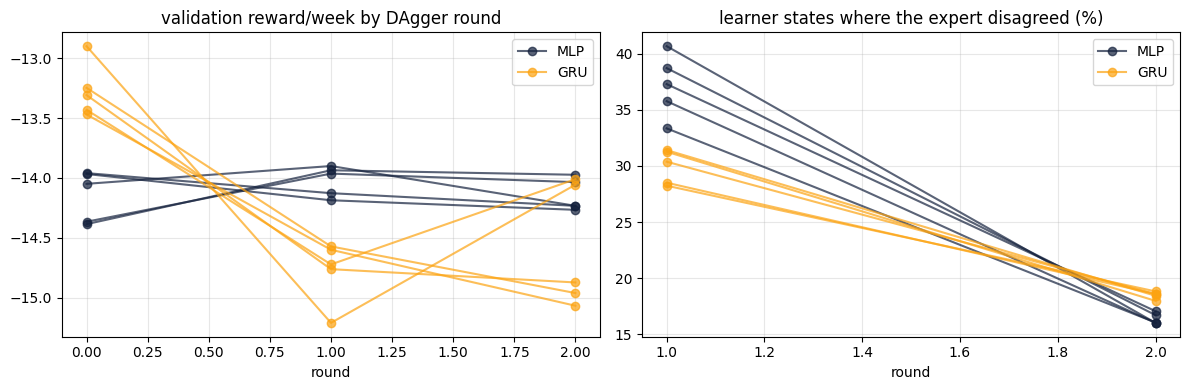

In [5]:
R = pd.concat([pd.read_csv(MOD / f"{n}_s{s}" / "rounds.csv").assign(net=n, seed=s) for n in NETS for s in range(5)], ignore_index=True)
R.to_csv(RES / "imitation_rounds.csv", index=False)
cols = ["reward_per_week", "LOLH_ess_h_per_home_month", "cut_demand_served_pct", "evening_import_kwh_per_day", "holdout_accuracy", "disagreement_pct"]
display(R.groupby(["net", "round"])[cols].agg(["mean", "std"]).round(3))
ch = {f"{n}_s{s}": json.loads((MOD / f"{n}_s{s}" / "done.json").read_text()) for n in NETS for s in range(5)}
for k, v in ch.items(): v["sha256"] = hashlib.sha256((MOD / k / "chosen.zip").read_bytes()).hexdigest()
(RES / "imitation_freeze.json").write_text(json.dumps(ch, indent=1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n, c in zip(NETS, ["#14213D", "#FCA311"]):
    for s in range(5):
        r = R[(R.net == n) & (R.seed == s)]; ax[0].plot(r["round"], r.reward_per_week, marker="o", color=c, alpha=.7, label=n if s == 0 else None)
        ax[1].plot(r["round"][1:], r.disagreement_pct[1:], marker="o", color=c, alpha=.7, label=n if s == 0 else None)
ax[0].set_title("validation reward/week by DAgger round"); ax[1].set_title("learner states where the expert disagreed (%)")
for a in ax: a.set_xlabel("round"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(RES / "figures" / "05_imitation.png", dpi=130); plt.show()